In [3]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import warnings, gc
warnings.filterwarnings('ignore')

plt.style.use('seaborn-v0_8-whitegrid')
pd.set_option('display.max_columns', 50)

COLS_TRANS = [
    'TransactionID', 'isFraud', 'TransactionDT', 'TransactionAmt',
    'ProductCD', 'card1', 'card2', 'card3', 'card4', 'card5', 'card6',
    'addr1', 'addr2', 'dist1', 'dist2',
    'P_emaildomain', 'R_emaildomain',
    'C1','C2','C3','C4','C5','C6','C7','C8','C9','C10','C11','C12','C13','C14',
    'D1','D2','D3','D4','D5','D6','D7','D8','D9','D10','D11','D12','D13','D14','D15',
    'M1','M2','M3','M4','M5','M6','M7','M8','M9',
]

COLS_ID = [
    'TransactionID', 'DeviceType', 'DeviceInfo',
]

DTYPE_TRANS = {
    'TransactionID': 'int32',  'isFraud': 'int8',
    'TransactionDT': 'int32',  'TransactionAmt': 'float32',
    'ProductCD': 'category',
    'card1': 'float32', 'card2': 'float32', 'card3': 'float32',
    'card4': 'category', 'card5': 'float32', 'card6': 'category',
    'addr1': 'float32', 'addr2': 'float32',
    'dist1': 'float32', 'dist2': 'float32',
    'P_emaildomain': 'category', 'R_emaildomain': 'category',
}

DTYPE_ID = {
    'TransactionID': 'int32',
    'DeviceType': 'category', 'DeviceInfo': 'category',
}

def load_cols(path, usecols, dtype_map, chunksize=80000):
    chunks, reader = [], pd.read_csv(
        path, usecols=usecols, dtype=dtype_map,
        chunksize=chunksize, low_memory=True
    )
    for i, chunk in enumerate(reader):
        chunks.append(chunk)
        if i % 3 == 0:
            print(f"  chunk {i} — {(i+1)*chunksize:,} rows...")
    out = pd.concat(chunks, ignore_index=True)
    del chunks; gc.collect()
    return out

print("Loading transactions (slim)...")
df_trans = load_cols('../data/raw/train_transaction.csv', COLS_TRANS, DTYPE_TRANS)
print(f"✓ {df_trans.shape}  |  {df_trans.memory_usage(deep=True).sum()/1e6:.0f} MB\n")

print("Loading identity...")
df_id = load_cols('../data/raw/train_identity.csv', COLS_ID, DTYPE_ID)
print(f"✓ {df_id.shape}  |  {df_id.memory_usage(deep=True).sum()/1e6:.0f} MB\n")


df = df_trans.merge(df_id, on='TransactionID', how='left')
del df_trans, df_id; gc.collect()

print(f"✓ Merged : {df.shape[0]:,} rows × {df.shape[1]} cols")
print(f"  Memory : {df.memory_usage(deep=True).sum()/1e6:.0f} MB")
print(f"  Fraud  : {df['isFraud'].mean():.4%}")

Loading transactions (slim)...
  chunk 0 — 80,000 rows...
  chunk 3 — 320,000 rows...
  chunk 6 — 560,000 rows...
✓ (590540, 55)  |  470 MB

Loading identity...
  chunk 0 — 80,000 rows...
✓ (144233, 3)  |  9 MB

✓ Merged : 590,540 rows × 57 cols
  Memory : 493 MB
  Fraud  : 3.4990%


In [4]:

df['hour']        = (df['TransactionDT'] // 3600) % 24
df['day_of_week'] = (df['TransactionDT'] // (3600 * 24)) % 7
df['day_of_month']= (df['TransactionDT'] // (3600 * 24)) % 30
df['is_weekend']  = (df['day_of_week'] >= 5).astype('int8')
df['is_night']    = (df['hour'].between(0, 5)).astype('int8')

print("Time features created:")
print(df[['hour','day_of_week','is_weekend','is_night']].head(3))

print(f"\nFraud rate — daytime : {df[df['is_night']==0]['isFraud'].mean():.4%}")
print(f"Fraud rate — night   : {df[df['is_night']==1]['isFraud'].mean():.4%}")

Time features created:
   hour  day_of_week  is_weekend  is_night
0     0            1           0         1
1     0            1           0         1
2     0            1           0         1

Fraud rate — daytime : 3.3936%
Fraud rate — night   : 3.8299%


In [5]:

df['log_amount'] = np.log1p(df['TransactionAmt']).astype('float32')

df['is_round_amount'] = (df['TransactionAmt'] % 1 == 0).astype('int8')

df['amt_mean_by_product'] = df.groupby('ProductCD')['TransactionAmt'] \
                              .transform('mean').astype('float32')

df['amt_std_by_product']  = df.groupby('ProductCD')['TransactionAmt'] \
                              .transform('std').astype('float32')

df['amt_zscore_product'] = (
    (df['TransactionAmt'] - df['amt_mean_by_product']) /
    (df['amt_std_by_product'] + 1e-9)  
).astype('float32')

print("Amount features created.")
print(df[['TransactionAmt','log_amount','is_round_amount','amt_zscore_product']].head(3))

Amount features created.
   TransactionAmt  log_amount  is_round_amount  amt_zscore_product
0            68.5    4.241327                0           -0.315028
1            29.0    3.401197                1           -0.462013
2            59.0    4.094345                1           -0.350379


In [6]:

df = df.sort_values('TransactionDT').reset_index(drop=True)

df['card1_day_count'] = df.groupby('card1')['TransactionDT'] \
                          .transform(lambda x: x.expanding().count()) \
                          .astype('int32')

df['card1_time_since_last'] = (
    df.groupby('card1')['TransactionDT']
      .transform(lambda x: x.diff())   
    / 3600                              
).astype('float32')

df['card1_time_since_last'] = df['card1_time_since_last'].fillna(9999)

df['card1_rapid_fire'] = (df['card1_time_since_last'] < 0.167).astype('int8')

print("Velocity features created.")
print(df[['card1','card1_day_count','card1_time_since_last','card1_rapid_fire']].head(10))

print(f"\nFraud rate — normal pace  : {df[df['card1_rapid_fire']==0]['isFraud'].mean():.4%}")
print(f"Fraud rate — rapid fire   : {df[df['card1_rapid_fire']==1]['isFraud'].mean():.4%}")

Velocity features created.
     card1  card1_day_count  card1_time_since_last  card1_rapid_fire
0  13926.0                1                 9999.0                 0
1   2755.0                1                 9999.0                 0
2   4663.0                1                 9999.0                 0
3  18132.0                1                 9999.0                 0
4   4497.0                1                 9999.0                 0
5   5937.0                1                 9999.0                 0
6  12308.0                1                 9999.0                 0
7  12695.0                1                 9999.0                 0
8   2803.0                1                 9999.0                 0
9  17399.0                1                 9999.0                 0

Fraud rate — normal pace  : 3.1111%
Fraud rate — rapid fire   : 5.1310%


In [8]:

HIGH_RISK_DOMAINS = {
    'gmail.com', 'yahoo.com', 'hotmail.com', 'outlook.com',
    'live.com', 'icloud.com', 'aol.com', 'protonmail.com',
    'mail.com', 'ymail.com', 'me.com'
}

df['P_email_highrisk'] = df['P_emaildomain'] \
                           .isin(HIGH_RISK_DOMAINS).astype('int8')
df['R_email_highrisk'] = df['R_emaildomain'] \
                           .isin(HIGH_RISK_DOMAINS).astype('int8')

df['email_domain_match'] = (
    df['P_emaildomain'] == df['R_emaildomain']
).astype('int8')

domain_fraud = df.groupby('P_emaildomain')['isFraud'] \
                 .agg(['mean','count']) \
                 .rename(columns={'mean':'fraud_rate','count':'volume'}) \
                 .sort_values('fraud_rate', ascending=False)

print("Top 10 riskiest email domains (min 100 transactions):")
print(domain_fraud[domain_fraud['volume'] > 100].head(10).round(4))

Top 10 riskiest email domains (min 100 transactions):
                fraud_rate  volume
P_emaildomain                     
mail.com            0.1896     559
outlook.es          0.1301     438
aim.com             0.1270     315
outlook.com         0.0946    5096
hotmail.es          0.0656     305
live.com.mx         0.0547     749
hotmail.com         0.0530   45250
gmail.com           0.0435  228355
yahoo.fr            0.0350     143
embarqmail.com      0.0346     260


In [9]:

df['card_type_fraud_rate'] = df.groupby('card4')['isFraud'] \
                               .transform('mean').astype('float32')

df['card1_total_txns'] = df.groupby('card1')['TransactionID'] \
                           .transform('count').astype('int32')

df['is_new_card'] = (df['card1_total_txns'] == 1).astype('int8')

print(f"New card fraud rate     : {df[df['is_new_card']==1]['isFraud'].mean():.4%}")
print(f"Existing card fraud rate: {df[df['is_new_card']==0]['isFraud'].mean():.4%}")

New card fraud rate     : 4.2393%
Existing card fraud rate: 3.4947%


In [10]:

INDICATOR_COLS = ['dist1', 'dist2', 'D1', 'D2', 'D3',
                  'P_emaildomain', 'R_emaildomain', 'DeviceType']

for col in INDICATOR_COLS:
    if col in df.columns:
        df[f'{col}_missing'] = df[col].isnull().astype('int8')

df['missing_count'] = df[[f'{c}_missing' for c in INDICATOR_COLS
                          if f'{c}_missing' in df.columns]].sum(axis=1).astype('int8')

print(f"Fraud rate by missing_count:")
print(df.groupby('missing_count')['isFraud'].mean().round(4))

Fraud rate by missing_count:
missing_count
1    0.0473
2    0.0828
3    0.0380
4    0.0431
5    0.0234
6    0.0161
7    0.0218
8    0.0282
Name: isFraud, dtype: float64


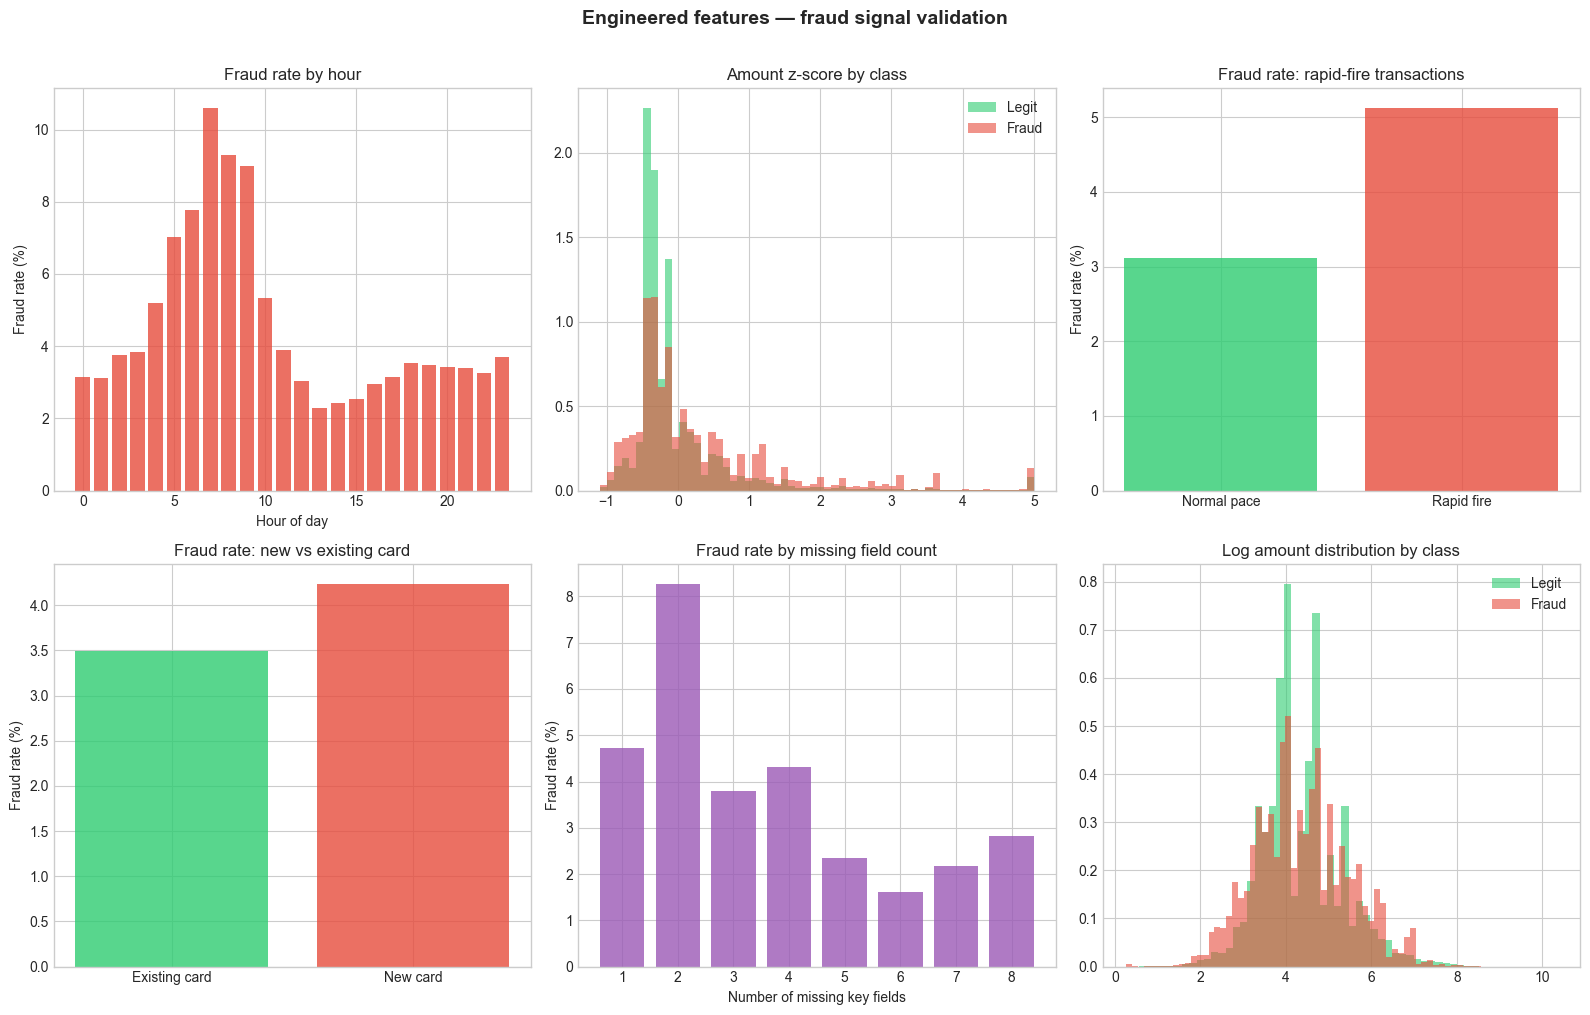

In [11]:
fig, axes = plt.subplots(2, 3, figsize=(16, 10))
fig.suptitle('Engineered features — fraud signal validation',
             fontsize=14, fontweight='bold', y=1.01)

hourly = df.groupby('hour')['isFraud'].mean() * 100
axes[0,0].bar(hourly.index, hourly.values, color='#e74c3c', alpha=0.8)
axes[0,0].set_title('Fraud rate by hour')
axes[0,0].set_xlabel('Hour of day')
axes[0,0].set_ylabel('Fraud rate (%)')

axes[0,1].hist(df[df['isFraud']==0]['amt_zscore_product'].clip(-5,5),
               bins=60, alpha=0.6, color='#2ecc71', label='Legit', density=True)
axes[0,1].hist(df[df['isFraud']==1]['amt_zscore_product'].clip(-5,5),
               bins=60, alpha=0.6, color='#e74c3c', label='Fraud', density=True)
axes[0,1].set_title('Amount z-score by class')
axes[0,1].legend()

rf_fraud = df.groupby('card1_rapid_fire')['isFraud'].mean() * 100
axes[0,2].bar(['Normal pace', 'Rapid fire'], rf_fraud.values,
              color=['#2ecc71', '#e74c3c'], alpha=0.8)
axes[0,2].set_title('Fraud rate: rapid-fire transactions')
axes[0,2].set_ylabel('Fraud rate (%)')

nc_fraud = df.groupby('is_new_card')['isFraud'].mean() * 100
axes[1,0].bar(['Existing card', 'New card'], nc_fraud.values,
              color=['#2ecc71', '#e74c3c'], alpha=0.8)
axes[1,0].set_title('Fraud rate: new vs existing card')
axes[1,0].set_ylabel('Fraud rate (%)')

mc_fraud = df.groupby('missing_count')['isFraud'].mean() * 100
axes[1,1].bar(mc_fraud.index, mc_fraud.values, color='#9b59b6', alpha=0.8)
axes[1,1].set_title('Fraud rate by missing field count')
axes[1,1].set_xlabel('Number of missing key fields')
axes[1,1].set_ylabel('Fraud rate (%)')

axes[1,2].hist(df[df['isFraud']==0]['log_amount'],
               bins=60, alpha=0.6, color='#2ecc71', label='Legit', density=True)
axes[1,2].hist(df[df['isFraud']==1]['log_amount'],
               bins=60, alpha=0.6, color='#e74c3c', label='Fraud', density=True)
axes[1,2].set_title('Log amount distribution by class')
axes[1,2].legend()

plt.tight_layout()
plt.savefig('../reports/engineered_features.png', dpi=150, bbox_inches='tight')
plt.show()

In [12]:

cols_to_drop = [col for col in df.columns
                if df[col].isnull().mean() > 0.80]
print(f"Dropping {len(cols_to_drop)} cols with >80% missing")

df_features = df.drop(columns=cols_to_drop)

cat_cols = df_features.select_dtypes(include='category').columns.tolist()
for col in cat_cols:
    df_features[col] = df_features[col].cat.codes.astype('int16')
    
print(f"Categorical columns encoded: {cat_cols}")
print(f"\nFinal feature set: {df_features.shape}")
print(f"Memory: {df_features.memory_usage(deep=True).sum()/1e6:.0f} MB")

df_features.to_parquet('../data/processed/02_features.parquet', index=False)
print("\n✓ Saved: data/processed/02_features.parquet")

Dropping 8 cols with >80% missing
Categorical columns encoded: ['ProductCD', 'card4', 'DeviceType']

Final feature set: (590540, 77)
Memory: 495 MB

✓ Saved: data/processed/02_features.parquet
